# Revisão de variáveis climáticas no modelo de dengue

A análise de correlação recomendou testar se clima acrescenta valor preditivo. Este notebook compara três especificações da mesma Binomial Negativa: (1) sem clima; (2) só temperatura; (3) temperatura, chuva e umidade. As origens walk-forward, os alvos, a população e o horizonte de quatro semanas são iguais.

A validação é temporal e sem embaralhamento. Clima usado em cada horizonte respeita a informação que estaria disponível na origem. Isso testa o ganho de previsão dos preditores climáticos, não causalidade.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_ablation_clima.py').exists(): ROOT = Path.cwd().parent
assert (ROOT / 'src' / 'model_ablation_clima.py').exists(), 'Abra o notebook dentro da pasta do projeto.'
panel = ROOT / 'data' / 'processed' / 'painel_capitais_modelagem.parquet'
if not panel.exists(): raise FileNotFoundError('Base tratada ausente. Use data/processed/painel_capitais_modelagem.parquet incluída nesta entrega.')
subprocess.run([sys.executable, str(ROOT / 'src' / 'model_ablation_clima.py'), '--n-origins', '24'], cwd=ROOT, check=True)
OUT = ROOT / 'reports' / 'modelagem_capitais'
TABLE = OUT / 'tables'
FIG = OUT / 'figures'

## Interpretação

MAE e RMSE estão em casos por semana. MASE compara o erro com o baseline sazonal. Confira também cobertura empírica e largura dos intervalos de 90%; intervalos muito estreitos podem acompanhar uma melhora de erro pontual.

In [2]:
display(Markdown((OUT / 'interpretacao_ablation_clima.md').read_text(encoding='utf-8')))
display(pd.read_csv(TABLE / 'comparacao_especificacoes_clima.csv'))

# Ablation de variáveis climáticas

As três especificações usam a mesma família (GLM Binomial Negativa), as mesmas 24 origens expansivas, os mesmos alvos e o mesmo horizonte 1–4 semanas. Em cada origem, treino contém apenas linhas até a origem; as features de clima respeitam o horizonte. Não houve embaralhamento.

## Especificações

- **Sem clima:** casos defasados (horizonte e 52 semanas), calendário e exposição populacional.
- **Só temperatura:** especificação anterior + temperatura, com lag mínimo 2 e lag pelo menos igual ao horizonte.
- **Três variáveis climáticas:** especificação anterior + temperatura, precipitação e umidade, com lags preferidos 2, 3 e 4 semanas (limitados pelo horizonte).

## Resultado e decisão

Menor RMSE: **Só temperatura**, RMSE=54.68, MAE=26.91, MASE=0.250. Diferença de RMSE da melhor especificação contra Sem clima: +2.40% (positivo significa erro menor). Veja cobertura e largura dos intervalos antes de preferir um modelo.

A especificação final do modelo de produção deve equilibrar RMSE, MAE, MASE e cobertura dos intervalos, não apenas correlações. Esta comparação avalia inclusão de clima no modelo NB selecionado; não substitui as comparações entre famílias de modelos. As métricas detalhadas por horizonte e capital estão nas tabelas CSV ao lado.

Origens: 21/01/2024 a 27/09/2026; uma origem por ponto espaçado no período recente. O conjunto de previsões foi salvo para auditoria.


,especificacao,MAE_casos_semana,RMSE_casos_semana,MAPE_pct_y_positivo,cobertura_MAPE_pct,sMAPE_pct,MASE,cobertura_intervalo90_pct,largura_intervalo90_media,n_previsoes
0,Só temperatura,26.914983,54.681217,42.071363,99.652778,32.175451,0.250024,98.611111,286.893519,864
1,Três variáveis climáticas,27.820426,55.549515,42.746598,99.652778,32.605021,0.258571,98.611111,289.033565,864
2,Sem clima,27.817624,56.025166,43.071009,99.652778,32.581001,0.256787,98.842593,290.914352,864


## Desempenho por horizonte e capital

Se o ganho aparece apenas em uma capital ou em um horizonte, a decisão deve ser conservadora. A comparação por capital ajuda a ver heterogeneidade regional.

In [3]:
display(pd.read_csv(TABLE / 'comparacao_especificacoes_clima_por_horizonte.csv'))
display(pd.read_csv(TABLE / 'comparacao_especificacoes_clima_por_capital.csv'))

,especificacao,horizonte_semanas,MAE_casos_semana,RMSE_casos_semana,MAPE_pct_y_positivo,cobertura_MAPE_pct,sMAPE_pct,MASE,cobertura_intervalo90_pct,largura_intervalo90_media,n_previsoes
0,Sem clima,1,16.269870,27.057276,24.036943,99.537037,22.367026,0.154677,100.000000,284.740741,216
1,Sem clima,2,22.532393,40.633983,38.683884,100.000000,28.727264,0.212185,99.537037,286.712963,216
2,Sem clima,3,31.496775,58.483242,45.760442,100.000000,34.675252,0.285553,98.611111,292.662037,216
3,Sem clima,4,40.971458,82.169158,63.907578,99.074074,44.554462,0.374736,97.222222,299.541667,216
4,Só temperatura,1,15.983291,26.716248,23.871637,99.537037,22.274898,0.152262,100.000000,283.648148,216
5,Só temperatura,2,21.404451,39.236953,37.715090,100.000000,28.211916,0.203159,99.537037,281.425926,216
6,Só temperatura,3,30.403333,56.316175,44.594722,100.000000,34.183461,0.277893,98.611111,287.833333,216
7,Só temperatura,4,39.868859,80.841413,62.206179,99.074074,44.031529,0.366782,96.296296,294.666667,216
8,Três variáveis climáticas,1,16.168673,27.294511,23.876391,99.537037,22.267026,0.153332,100.000000,284.097222,216
9,Três variáveis climáticas,2,21.713292,39.502825,37.871575,100.000000,28.422304,0.205677,99.537037,281.916667,216


,especificacao,capital,horizonte_semanas,MAE_casos_semana,RMSE_casos_semana,MAPE_pct_y_positivo,cobertura_MAPE_pct,sMAPE_pct,MASE,cobertura_intervalo90_pct,largura_intervalo90_media,n_previsoes
0,Sem clima,Aracaju,1,4.089105,5.436763,39.723946,95.833333,40.371578,0.128615,100.000000,42.166667,24
1,Sem clima,Aracaju,2,5.198179,6.633372,99.979885,100.000000,48.198222,0.161916,100.000000,43.833333,24
2,Sem clima,Aracaju,3,4.320249,5.609500,43.422576,100.000000,35.135082,0.136930,100.000000,45.166667,24
3,Sem clima,Aracaju,4,8.072331,10.148703,102.563238,95.833333,66.720879,0.257271,95.833333,47.250000,24
4,Sem clima,Fortaleza,1,11.405831,15.629550,37.122884,100.000000,29.460811,0.052484,100.000000,151.333333,24
...,...,...,...,...,...,...,...,...,...,...,...,...
103,Três variáveis climáticas,São Luís,4,22.168606,31.092562,47.238893,95.833333,49.185226,0.601787,91.666667,149.083333,24
104,Três variáveis climáticas,Teresina,1,24.673504,47.744981,21.050569,100.000000,17.582634,0.256534,100.000000,421.125000,24
105,Três variáveis climáticas,Teresina,2,33.609322,77.420575,21.419150,100.000000,21.620983,0.352125,100.000000,419.375000,24
106,Três variáveis climáticas,Teresina,3,30.502632,46.742582,29.234677,100.000000,26.293796,0.315250,100.000000,421.791667,24


## Visualização

O gráfico mostra o RMSE por horizonte para as três variantes. A figura também está em `reports/modelagem_capitais/figures/04_ablation_clima_rmse.png`.

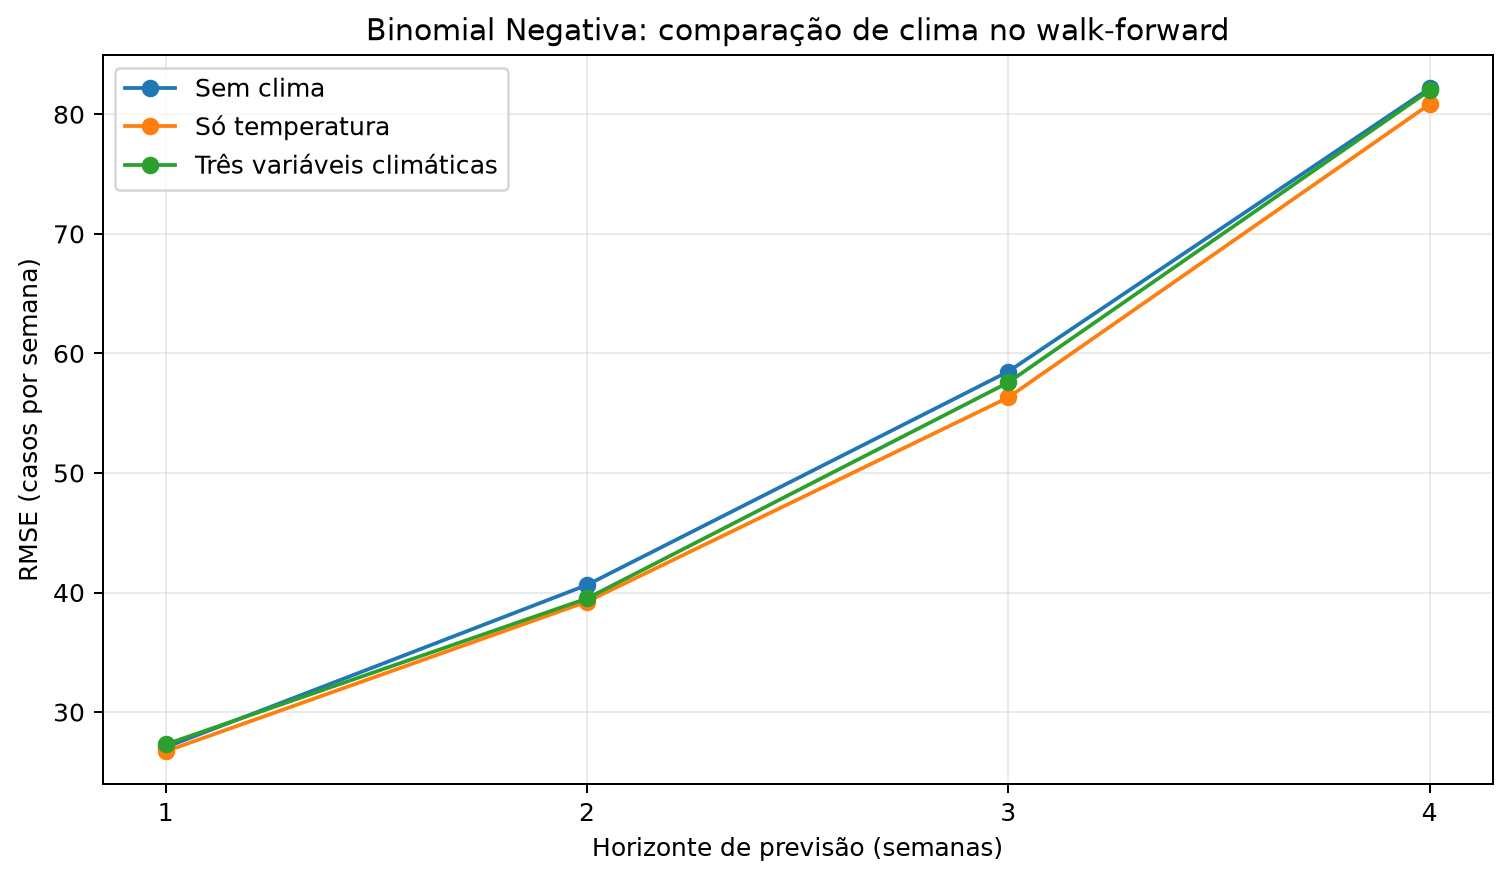

In [4]:
display(Image(filename=str(FIG / '04_ablation_clima_rmse.png')))
